In [12]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
# Load the customer churn dataset

file_path = r"C:\Users\sarva\OneDrive\Desktop\Customer_Churn_Project\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


In [14]:
print("Number of columns:", len(df.columns))
print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(i, "→", column)

Number of columns: 21

Column names:
1 → customerID
2 → gender
3 → SeniorCitizen
4 → Partner
5 → Dependents
6 → tenure
7 → PhoneService
8 → MultipleLines
9 → InternetService
10 → OnlineSecurity
11 → OnlineBackup
12 → DeviceProtection
13 → TechSupport
14 → StreamingTV
15 → StreamingMovies
16 → Contract
17 → PaperlessBilling
18 → PaymentMethod
19 → MonthlyCharges
20 → TotalCharges
21 → Churn


In [15]:
print(df.shape)
print(df.columns.tolist())

(7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [18]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [19]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [20]:
# Count customers who churned and stayed

print(df["Churn"].value_counts())

print("\nPercentage distribution:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage distribution:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [21]:
# Check the data type of TotalCharges
print("Data type:", df["TotalCharges"].dtype)

# Find blank values
blank_total_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()

print("Blank TotalCharges values:", blank_total_charges)

Data type: object
Blank TotalCharges values: 11


In [22]:
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Data type after conversion:", df["TotalCharges"].dtype)
print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())

Data type after conversion: float64
Missing TotalCharges values: 11


In [19]:
# Check the rows where TotalCharges is missing

df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [23]:
# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing TotalCharges after cleaning:",
      df["TotalCharges"].isnull().sum())

Missing TotalCharges after cleaning: 0


In [24]:
# Remove customerID because it is only an identifier
df = df.drop("customerID", axis=1)

print("Dataset shape after removing customerID:", df.shape)

Dataset shape after removing customerID: (7043, 20)


In [25]:
# Final cleaning check

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Shape: (7043, 20)

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


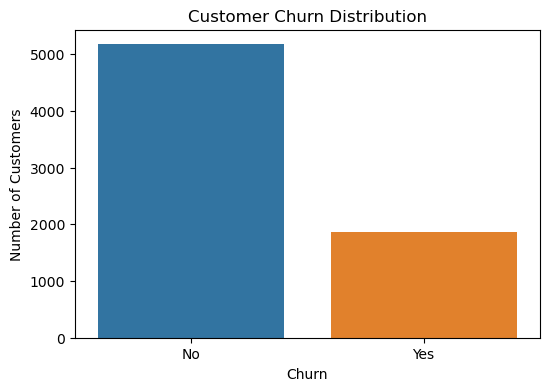

In [26]:
# Churn distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [27]:
# Calculate churn percentage

churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


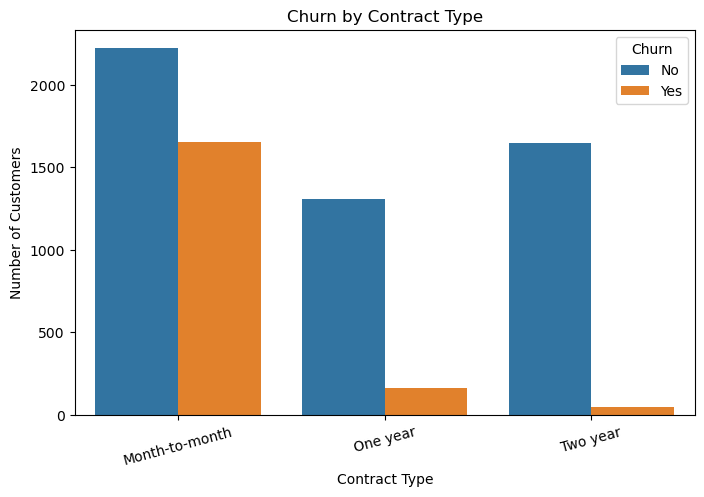

In [28]:
# Churn by contract type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

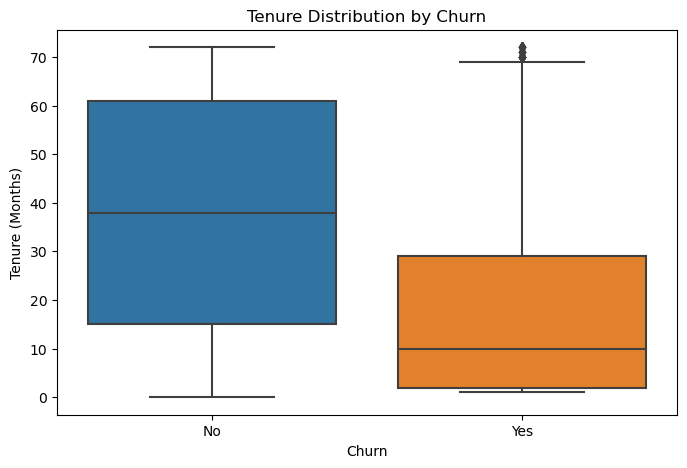

In [29]:
# Compare tenure for churned and non-churned customers

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

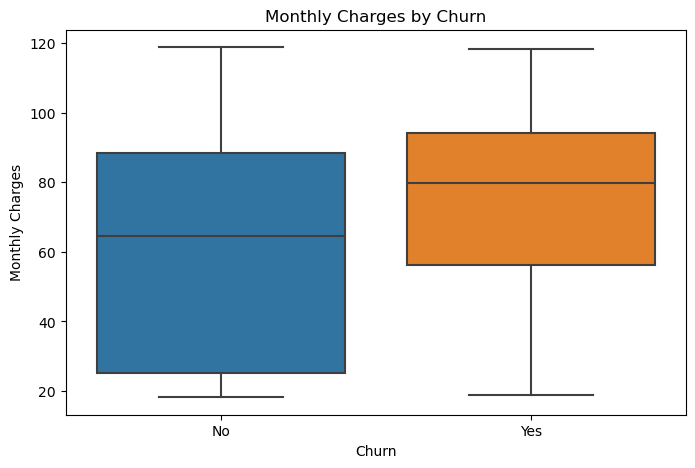

In [30]:
# Compare monthly charges for churned and non-churned customers

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

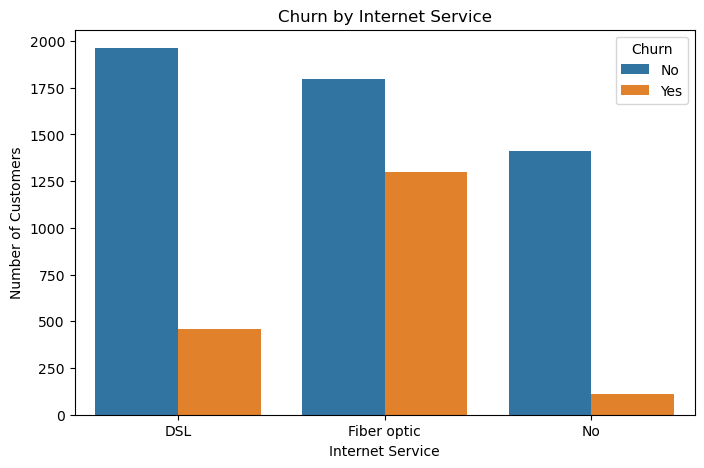

In [31]:
# Churn by Internet Service

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

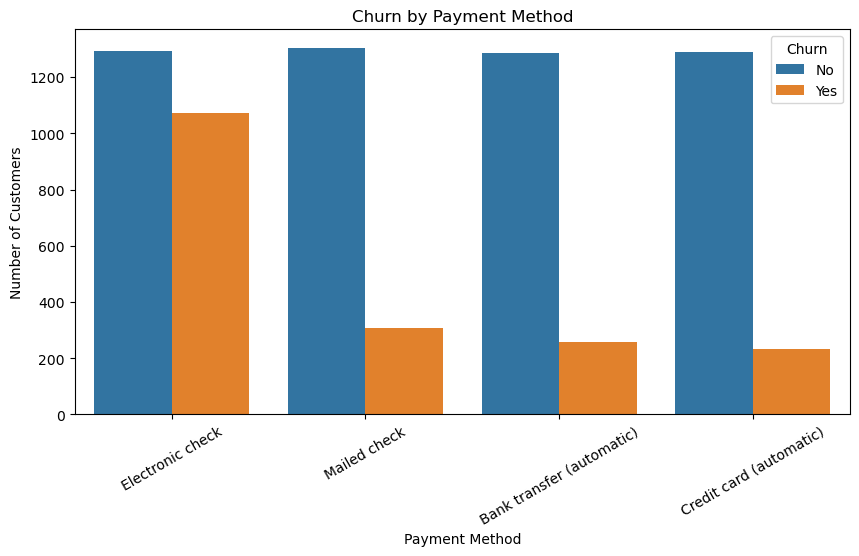

In [32]:
# Churn by Payment Method

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

In [33]:
# Churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [34]:
# Churn rate by internet service

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


In [35]:
# Churn rate by payment method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


In [36]:
# Churn rate by gender

gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print(gender_churn.round(2))

Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


In [37]:
# Churn rate by senior citizen status

senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn.round(2))

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


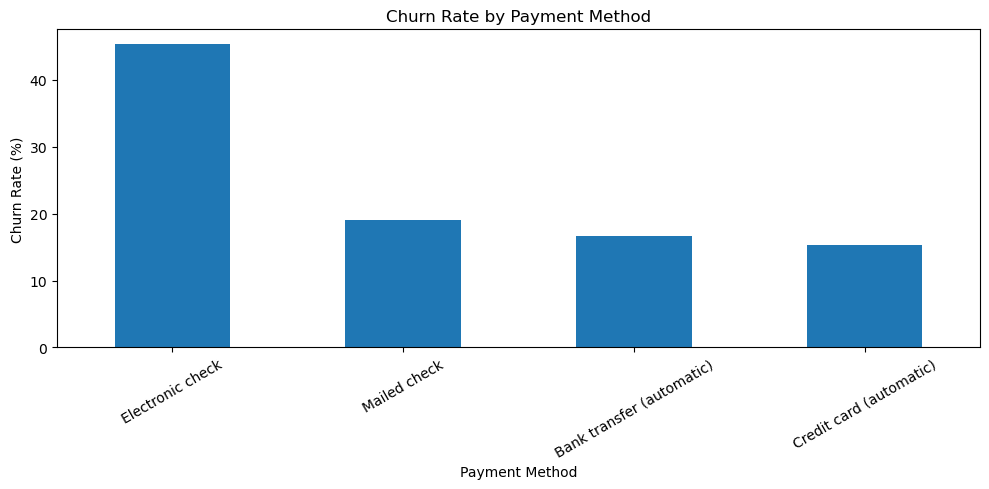

In [38]:
# Visualize churn percentage by payment method

payment_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [39]:
# Separate input features and target variable

X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [40]:
# Identify numerical and categorical columns

numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

print("Numerical columns:")
print(list(numerical_cols))

print("\nCategorical columns:")
print(list(categorical_cols))

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5634, 19)
Testing data shape: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [43]:
from sklearn.pipeline import Pipeline

# Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [44]:
# Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [45]:
# Make predictions on test data

y_pred_lr = logistic_model.predict(X_test)
y_pred_dt = decision_tree_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [46]:
# Calculate evaluation metrics

# Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

# Decision Tree
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

print("LOGISTIC REGRESSION")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-score :", round(lr_f1, 4))

print("\nDECISION TREE")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1-score :", round(dt_f1, 4))

LOGISTIC REGRESSION
Accuracy : 0.802
Precision: 0.648
Recall   : 0.5561
F1-score : 0.5986

DECISION TREE
Accuracy : 0.7197
Precision: 0.473
Recall   : 0.492
F1-score : 0.4823


In [47]:
# Confusion matrices

cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

print("\nDecision Tree Confusion Matrix:")
print(cm_dt)

Logistic Regression Confusion Matrix:
[[922 113]
 [166 208]]

Decision Tree Confusion Matrix:
[[830 205]
 [190 184]]


In [48]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy],
    "Precision": [lr_precision, dt_precision],
    "Recall": [lr_recall, dt_recall],
    "F1-Score": [lr_f1, dt_f1]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.801987,0.647975,0.556150,0.598561
1,Decision Tree,0.719659,0.473008,0.491979,0.482307


In [49]:
model_comparison_display = model_comparison.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    model_comparison_display[column] = (
        model_comparison_display[column] * 100
    ).round(2).astype(str) + "%"

model_comparison_display

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,80.2%,64.8%,55.61%,59.86%
1,Decision Tree,71.97%,47.3%,49.2%,48.23%


In [50]:
# Improved Logistic Regression with class balancing
from sklearn.pipeline import Pipeline
logistic_balanced_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [51]:
# Predictions from balanced Logistic Regression

y_pred_lr_balanced = logistic_balanced_model.predict(X_test)

print("Balanced Logistic Regression predictions completed!")

Balanced Logistic Regression predictions completed!


In [52]:
# Evaluate balanced Logistic Regression

lr_balanced_accuracy = accuracy_score(y_test, y_pred_lr_balanced)
lr_balanced_precision = precision_score(y_test, y_pred_lr_balanced)
lr_balanced_recall = recall_score(y_test, y_pred_lr_balanced)
lr_balanced_f1 = f1_score(y_test, y_pred_lr_balanced)

print("BALANCED LOGISTIC REGRESSION")
print("Accuracy :", round(lr_balanced_accuracy, 4))
print("Precision:", round(lr_balanced_precision, 4))
print("Recall   :", round(lr_balanced_recall, 4))
print("F1-score :", round(lr_balanced_f1, 4))

BALANCED LOGISTIC REGRESSION
Accuracy : 0.7495
Precision: 0.5187
Recall   : 0.7807
F1-score : 0.6233


In [53]:
cm_lr_balanced = confusion_matrix(
    y_test,
    y_pred_lr_balanced
)

print("Balanced Logistic Regression Confusion Matrix:")
print(cm_lr_balanced)

Balanced Logistic Regression Confusion Matrix:
[[764 271]
 [ 82 292]]


In [54]:
print("Classification Report - Balanced Logistic Regression")
print(
    classification_report(
        y_test,
        y_pred_lr_balanced,
        target_names=["No Churn", "Churn"]
    )
)

Classification Report - Balanced Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81      1035
       Churn       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



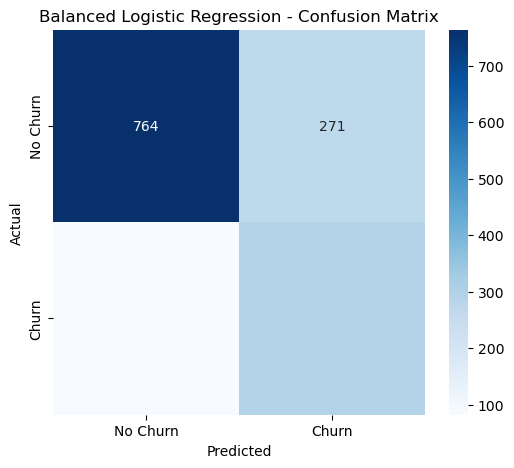

In [55]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [56]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    logistic_balanced_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("5-Fold Cross-Validation F1 Scores:")
print(cv_scores)

print("\nMean F1-score:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

5-Fold Cross-Validation F1 Scores:
[0.65679677 0.64456233 0.64324324 0.61103979 0.59306804]

Mean F1-score: 0.6297
Standard Deviation: 0.0238


In [57]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search_lr = GridSearchCV(
    estimator=logistic_balanced_model,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search_lr.fit(X_train, y_train)

print("Best parameters:")
print(grid_search_lr.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search_lr.best_score_, 4))

Best parameters:
{'classifier__C': 1, 'classifier__solver': 'liblinear'}

Best cross-validation F1-score:
0.6326


In [58]:
best_lr_model = grid_search_lr.best_estimator_

# Predictions on test data
y_pred_lr_tuned = best_lr_model.predict(X_test)

# Calculate metrics
tuned_lr_accuracy = accuracy_score(y_test, y_pred_lr_tuned)
tuned_lr_precision = precision_score(y_test, y_pred_lr_tuned)
tuned_lr_recall = recall_score(y_test, y_pred_lr_tuned)
tuned_lr_f1 = f1_score(y_test, y_pred_lr_tuned)

print("TUNED BALANCED LOGISTIC REGRESSION")
print("Accuracy :", round(tuned_lr_accuracy, 4))
print("Precision:", round(tuned_lr_precision, 4))
print("Recall   :", round(tuned_lr_recall, 4))
print("F1-score :", round(tuned_lr_f1, 4))

TUNED BALANCED LOGISTIC REGRESSION
Accuracy : 0.7374
Precision: 0.5034
Recall   : 0.7888
F1-score : 0.6146


In [59]:
param_grid_dt = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__class_weight": [None, "balanced"]
}

grid_search_dt = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search_dt.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(grid_search_dt.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search_dt.best_score_, 4))

Best Decision Tree parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best cross-validation F1-score:
0.6204


In [60]:
best_dt_model = grid_search_dt.best_estimator_

# Predictions on test data
y_pred_dt_tuned = best_dt_model.predict(X_test)

# Calculate metrics
tuned_dt_accuracy = accuracy_score(y_test, y_pred_dt_tuned)
tuned_dt_precision = precision_score(y_test, y_pred_dt_tuned)
tuned_dt_recall = recall_score(y_test, y_pred_dt_tuned)
tuned_dt_f1 = f1_score(y_test, y_pred_dt_tuned)

print("TUNED BALANCED DECISION TREE")
print("Accuracy :", round(tuned_dt_accuracy, 4))
print("Precision:", round(tuned_dt_precision, 4))
print("Recall   :", round(tuned_dt_recall, 4))
print("F1-score :", round(tuned_dt_f1, 4))

TUNED BALANCED DECISION TREE
Accuracy : 0.7459
Precision: 0.514
Recall   : 0.7834
F1-score : 0.6208


In [61]:
# Get churn probability for each test customer
y_prob_lr = logistic_balanced_model.predict_proba(X_test)[:, 1]

print("First 10 churn probabilities:")
print(y_prob_lr[:10])

First 10 churn probabilities:
[0.13637343 0.85588236 0.16210919 0.63482792 0.07774271 0.80852758
 0.67194069 0.27945574 0.01355125 0.64710546]


In [62]:
def get_risk_level(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    else:
        return "High"


risk_levels = [get_risk_level(prob) for prob in y_prob_lr]

risk_df = pd.DataFrame({
    "Churn Probability": y_prob_lr,
    "Risk Level": risk_levels
})

print(risk_df.head(10))

   Churn Probability Risk Level
0           0.136373        Low
1           0.855882       High
2           0.162109        Low
3           0.634828       High
4           0.077743        Low
5           0.808528       High
6           0.671941       High
7           0.279456        Low
8           0.013551        Low
9           0.647105       High


In [63]:
print("\nRisk Level Distribution:")
print(risk_df["Risk Level"].value_counts())


Risk Level Distribution:
Risk Level
Low       605
High      474
Medium    330
Name: count, dtype: int64


In [64]:
# Training predictions
y_train_pred = logistic_balanced_model.predict(X_train)

# Training metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)

print("BALANCED LOGISTIC REGRESSION - TRAINING PERFORMANCE")
print("Accuracy :", round(train_accuracy, 4))
print("Precision:", round(train_precision, 4))
print("Recall   :", round(train_recall, 4))
print("F1-score :", round(train_f1, 4))

BALANCED LOGISTIC REGRESSION - TRAINING PERFORMANCE
Accuracy : 0.7574
Precision: 0.5285
Recall   : 0.794
F1-score : 0.6346


In [65]:
# Confusion Matrix for Balanced Logistic Regression
cm_final = confusion_matrix(y_test, y_pred_lr_balanced)

print("Confusion Matrix:")
print(cm_final)

Confusion Matrix:
[[764 271]
 [ 82 292]]


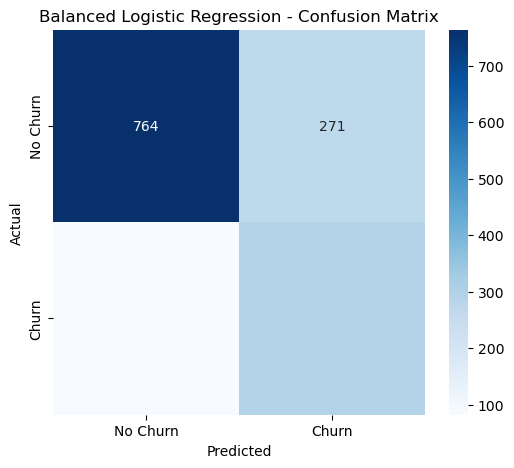

In [66]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [67]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr_balanced,
        target_names=["No Churn", "Churn"]
    )
)

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81      1035
       Churn       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [68]:
# Get the trained Logistic Regression classifier
lr_classifier = logistic_balanced_model.named_steps["classifier"]

# Get feature names after One-Hot Encoding
feature_names = (
    logistic_balanced_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get coefficients
coefficients = lr_classifier.coef_[0]

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate absolute importance
feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

# Sort by importance
feature_importance = feature_importance.sort_values(
    "Absolute Importance",
    ascending=False
)

print(feature_importance.head(20))

                                         Feature  Coefficient  \
36                  cat__Contract_Month-to-month     0.516785   
38                        cat__Contract_Two year    -0.427720   
43           cat__PaymentMethod_Electronic check     0.324068   
15                      cat__InternetService_DSL    -0.272480   
20                       cat__OnlineSecurity_Yes    -0.266419   
16              cat__InternetService_Fiber optic     0.265032   
18                        cat__OnlineSecurity_No     0.258970   
29                          cat__TechSupport_Yes    -0.247466   
27                           cat__TechSupport_No     0.240017   
12                         cat__MultipleLines_No    -0.217804   
11                         cat__PhoneService_Yes    -0.206734   
39                      cat__PaperlessBilling_No    -0.199707   
0                             num__SeniorCitizen     0.186274   
37                        cat__Contract_One year    -0.149813   
13           cat__Multipl

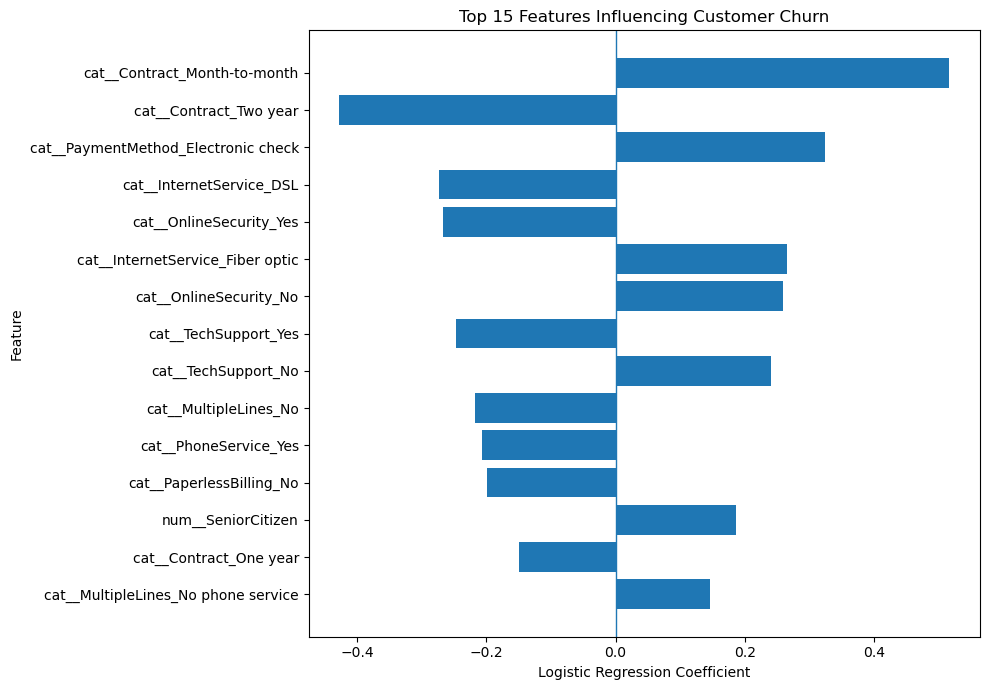

In [69]:
# Top 15 features by absolute importance
top_features = feature_importance.head(15).sort_values(
    "Absolute Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [70]:
def explain_customer(customer_data, model, top_n=5):
    """
    Explain why a customer is predicted to have higher/lower churn risk.
    """

    # Get preprocessor and classifier
    preprocessor = model.named_steps["preprocessor"]
    classifier = model.named_steps["classifier"]

    # Transform customer data
    transformed_data = preprocessor.transform(customer_data)

    # Get feature names
    feature_names = preprocessor.get_feature_names_out()

    # Get coefficients
    coefficients = classifier.coef_[0]

    # Calculate contribution of each feature
    contributions = transformed_data[0] * coefficients

    # Convert to dataframe
    explanation = pd.DataFrame({
        "Feature": feature_names,
        "Contribution": contributions
    })

    # Convert sparse value if necessary
    explanation["Contribution"] = explanation["Contribution"].astype(float)

    # Separate positive and negative contributions
    positive = explanation[
        explanation["Contribution"] > 0
    ].sort_values(
        "Contribution",
        ascending=False
    ).head(top_n)

    negative = explanation[
        explanation["Contribution"] < 0
    ].sort_values(
        "Contribution"
    ).head(top_n)

    return positive, negative

In [71]:
# Select one customer from test data
sample_customer = X_test.iloc[[0]]

# Get prediction and probability
sample_prediction = logistic_balanced_model.predict(sample_customer)[0]
sample_probability = logistic_balanced_model.predict_proba(
    sample_customer
)[0][1]

# Get explanation
positive_factors, negative_factors = explain_customer(
    sample_customer,
    logistic_balanced_model
)

print("Churn Prediction:",
      "Churn" if sample_prediction == 1 else "No Churn")

print("Churn Probability:",
      round(sample_probability * 100, 2), "%")

print("\nFactors pushing toward CHURN:")
print(positive_factors)

print("\nFactors pushing toward NO CHURN:")
print(negative_factors)

Churn Prediction: No Churn
Churn Probability: 13.64 %

Factors pushing toward CHURN:
                             Feature  Contribution
3                  num__TotalCharges      1.540970
2                num__MonthlyCharges      1.141760
16  cat__InternetService_Fiber optic      0.265032
40         cat__PaperlessBilling_Yes      0.138958
35          cat__StreamingMovies_Yes      0.091203

Factors pushing toward NO CHURN:
                    Feature  Contribution
1               num__tenure     -3.472567
38   cat__Contract_Two year     -0.427720
20  cat__OnlineSecurity_Yes     -0.266419
29     cat__TechSupport_Yes     -0.247466
11    cat__PhoneService_Yes     -0.206734


In [72]:
def clean_feature_name(feature):
    """
    Convert encoded feature names into user-friendly names.
    """

    feature = feature.replace("num__", "")
    feature = feature.replace("cat__", "")

    replacements = {
        "Contract_Month-to-month": "Month-to-month contract",
        "Contract_One year": "One-year contract",
        "Contract_Two year": "Two-year contract",
        "PaymentMethod_Electronic check": "Electronic check payment",
        "PaymentMethod_Credit card (automatic)": "Automatic credit card payment",
        "PaymentMethod_Bank transfer (automatic)": "Automatic bank transfer",
        "PaymentMethod_Mailed check": "Mailed check payment",
        "InternetService_Fiber optic": "Fiber optic internet",
        "InternetService_DSL": "DSL internet",
        "InternetService_No": "No internet service",
        "OnlineSecurity_Yes": "Online security enabled",
        "OnlineSecurity_No": "No online security",
        "OnlineBackup_Yes": "Online backup enabled",
        "OnlineBackup_No": "No online backup",
        "DeviceProtection_Yes": "Device protection enabled",
        "DeviceProtection_No": "No device protection",
        "TechSupport_Yes": "Technical support enabled",
        "TechSupport_No": "No technical support",
        "PaperlessBilling_Yes": "Paperless billing",
        "PaperlessBilling_No": "No paperless billing",
        "PhoneService_Yes": "Phone service",
        "PhoneService_No": "No phone service",
        "MultipleLines_Yes": "Multiple phone lines",
        "MultipleLines_No": "No multiple lines",
        "MultipleLines_No phone service": "No phone service",
        "Dependents_Yes": "Has dependents",
        "Dependents_No": "No dependents",
        "Partner_Yes": "Has a partner",
        "Partner_No": "No partner",
        "StreamingTV_Yes": "Streaming TV enabled",
        "StreamingTV_No": "No streaming TV",
        "StreamingMovies_Yes": "Streaming movies enabled",
        "StreamingMovies_No": "No streaming movies",
        "gender_Male": "Male",
        "gender_Female": "Female",
        "SeniorCitizen": "Senior citizen",
        "tenure": "Customer tenure",
        "MonthlyCharges": "Monthly charges",
        "TotalCharges": "Total charges"
    }

    return replacements.get(feature, feature)

In [73]:
# Apply human-readable names
positive_factors["Readable Feature"] = (
    positive_factors["Feature"].apply(clean_feature_name)
)

negative_factors["Readable Feature"] = (
    negative_factors["Feature"].apply(clean_feature_name)
)

print("Factors pushing toward CHURN:")
print(positive_factors[["Readable Feature", "Contribution"]])

print("\nFactors pushing toward NO CHURN:")
print(negative_factors[["Readable Feature", "Contribution"]])

Factors pushing toward CHURN:
            Readable Feature  Contribution
3              Total charges      1.540970
2            Monthly charges      1.141760
16      Fiber optic internet      0.265032
40         Paperless billing      0.138958
35  Streaming movies enabled      0.091203

Factors pushing toward NO CHURN:
             Readable Feature  Contribution
1             Customer tenure     -3.472567
38          Two-year contract     -0.427720
20    Online security enabled     -0.266419
29  Technical support enabled     -0.247466
11              Phone service     -0.206734


In [74]:
def predict_customer_risk(customer_data):
    """
    Predict churn risk and provide an explanation for one customer.
    """

    # Prediction
    prediction = logistic_balanced_model.predict(customer_data)[0]

    # Churn probability
    probability = logistic_balanced_model.predict_proba(
        customer_data
    )[0][1]

    # Risk level
    if probability < 0.30:
        risk = "Low"
    elif probability < 0.60:
        risk = "Medium"
    else:
        risk = "High"

    # Get explanation
    positive_factors, negative_factors = explain_customer(
        customer_data,
        logistic_balanced_model,
        top_n=5
    )

    # Convert feature names to readable names
    positive_reasons = [
        clean_feature_name(feature)
        for feature in positive_factors["Feature"]
    ]

    negative_reasons = [
        clean_feature_name(feature)
        for feature in negative_factors["Feature"]
    ]

    return {
        "prediction": "Churn" if prediction == 1 else "No Churn",
        "churn_probability": round(probability * 100, 2),
        "risk_level": risk,
        "risk_factors": positive_reasons,
        "protective_factors": negative_reasons
    }

In [75]:
result = predict_customer_risk(sample_customer)

print("Prediction:", result["prediction"])
print("Churn Probability:", result["churn_probability"], "%")
print("Risk Level:", result["risk_level"])

print("\nRisk Factors:")
for factor in result["risk_factors"]:
    print("-", factor)

print("\nProtective Factors:")
for factor in result["protective_factors"]:
    print("-", factor)

Prediction: No Churn
Churn Probability: 13.64 %
Risk Level: Low

Risk Factors:
- Total charges
- Monthly charges
- Fiber optic internet
- Paperless billing
- Streaming movies enabled

Protective Factors:
- Customer tenure
- Two-year contract
- Online security enabled
- Technical support enabled
- Phone service


In [76]:
def get_retention_recommendations(customer_data, risk_level):
    recommendations = []

    if risk_level == "Low":
        recommendations.append(
            "Continue regular customer engagement and service monitoring."
        )

    else:
        if customer_data["Contract"].iloc[0] == "Month-to-month":
            recommendations.append(
                "Offer an incentive for upgrading to a longer-term contract."
            )

        if customer_data["PaymentMethod"].iloc[0] == "Electronic check":
            recommendations.append(
                "Consider encouraging automatic payment methods."
            )

        if customer_data["OnlineSecurity"].iloc[0] == "No":
            recommendations.append(
                "Offer or explain the benefits of online security services."
            )

        if customer_data["TechSupport"].iloc[0] == "No":
            recommendations.append(
                "Offer technical support or a support-inclusive plan."
            )

        if customer_data["MonthlyCharges"].iloc[0] > 70:
            recommendations.append(
                "Review the customer's plan and consider a suitable pricing option."
            )

        if customer_data["tenure"].iloc[0] < 12:
            recommendations.append(
                "Provide additional onboarding and early-stage customer support."
            )

    if not recommendations:
        recommendations.append(
            "Monitor the customer and provide personalized engagement."
        )

    return recommendations

In [77]:
recommendations = get_retention_recommendations(
    sample_customer,
    result["risk_level"]
)

print("Retention Recommendations:")

for recommendation in recommendations:
    print("-", recommendation)

Retention Recommendations:
- Continue regular customer engagement and service monitoring.


In [78]:
def generate_recommendations(customer_data, risk_factors, risk_level):
    recommendations = []

    # If risk is low
    if risk_level == "Low":
        return [
            "Maintain regular engagement and continue monitoring customer satisfaction."
        ]

    # Generate recommendations based on actual customer factors

    if "Month-to-month contract" in risk_factors:
        recommendations.append(
            "Consider offering a personalized incentive to move the customer "
            "to a longer-term contract."
        )

    if "Electronic check payment" in risk_factors:
        recommendations.append(
            "Consider encouraging the customer to use an automatic payment method."
        )

    if "No online security" in risk_factors:
        recommendations.append(
            "Consider offering online security services or explaining their benefits."
        )

    if "No technical support" in risk_factors:
        recommendations.append(
            "Consider offering technical support or a support-inclusive plan."
        )

    if "Fiber optic internet" in risk_factors:
        recommendations.append(
            "Review the customer's internet plan and provide suitable "
            "service or pricing options."
        )

    if "Monthly charges" in risk_factors:
        recommendations.append(
            "Review the customer's current plan and consider a suitable "
            "pricing or plan adjustment."
        )

    if "Paperless billing" in risk_factors:
        recommendations.append(
            "Review billing preferences and ensure the customer understands "
            "available payment and billing options."
        )

    if "Streaming movies enabled" in risk_factors:
        recommendations.append(
            "Review the customer's subscribed services and provide "
            "a suitable bundled plan if available."
        )

    # Generic fallback
    if not recommendations:
        recommendations.append(
            "Provide personalized customer engagement and monitor "
            "the customer's future churn risk."
        )

    return recommendations

In [79]:
recommendations = generate_recommendations(
    sample_customer,
    result["risk_factors"],
    result["risk_level"]
)

print("Automatically Generated Recommendations:")

for recommendation in recommendations:
    print("-", recommendation)

Automatically Generated Recommendations:
- Maintain regular engagement and continue monitoring customer satisfaction.


In [82]:
import joblib
model = joblib.load("models/churn_model.pkl")

In [81]:
import os
import joblib

# Create the 'models' folder if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save your trained model
joblib.dump(logistic_balanced_model, "models/churn_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [83]:
import joblib

# Load the saved model
loaded_model = joblib.load("models/churn_model.pkl")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [85]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\sarva


In [86]:
print("\nFiles and folders:")
print(os.listdir())


Files and folders:
['.anaconda', '.cache', '.conda', '.condarc', '.continuum', '.copilot', '.docker', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jdks', '.jupyter', '.keras', '.lesshst', '.m2', '.matplotlib', '.python_history', '.streamlit', '.viminfo', '.vscode', '.vscode-shared', 'AMD_Classification_Updated_Trained (2).ipynb', 'anaconda3', 'AppData', 'Application Data', 'classification_report.csv', 'combined_dataset', 'Cookies', 'Customer_Churn_Analysis.ipynb', 'Downloads', 'effnetb0_final.pt', 'effnetb0_fold1.pt', 'effnetb0_fold2.pt', 'Favorites', 'helloworld', 'IdeaProjects', 'java', 'Links', 'Local Settings', 'metadata.csv', 'metadata_clean.csv', 'metadata_clean_final.csv', 'metadata_fixed.csv', 'MiniProject.ipynb', 'model.pth', 'models', 'mp2-Copy1.ipynb', 'mp2.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{7b33d2c1-54b2-11f0-bf80-a9de2672b005}.TM.blf', 'NTUSER.DAT{7b33d2c1-54b2-11f0-bf80-a9de2672b005}

In [87]:
import os

print(os.listdir("models"))

['churn_model.pkl']


In [89]:
import os
import joblib

model_path = r"C:\Users\sarva\models\churn_model.pkl"

joblib.dump(logistic_balanced_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: C:\Users\sarva\models\churn_model.pkl


In [88]:
print("logistic_balanced_model" in globals())
print("X_train" in globals())
print("y_train" in globals())

True
True
True


In [90]:
# Make predictions using the loaded model
y_test_pred = loaded_model.predict(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("Model Testing Results")
print("---------------------")
print("Accuracy :", round(test_accuracy * 100, 2), "%")
print("Precision:", round(test_precision * 100, 2), "%")
print("Recall   :", round(test_recall * 100, 2), "%")
print("F1-Score :", round(test_f1 * 100, 2), "%")

Model Testing Results
---------------------
Accuracy : 74.95 %
Precision: 51.87 %
Recall   : 78.07 %
F1-Score : 62.33 %


In [91]:
# Select one customer from the test dataset
test_customer = X_test.iloc[[0]]

print("Customer details:")
display(test_customer)

Customer details:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


In [92]:
# Predict this customer's churn risk
result = predict_customer_risk(test_customer)

print("Prediction:", result["prediction"])
print("Churn Probability:", result["churn_probability"], "%")
print("Risk Level:", result["risk_level"])

print("\nRisk Factors:")
for factor in result["risk_factors"]:
    print("-", factor)

print("\nProtective Factors:")
for factor in result["protective_factors"]:
    print("-", factor)

Prediction: No Churn
Churn Probability: 13.64 %
Risk Level: Low

Risk Factors:
- Total charges
- Monthly charges
- Fiber optic internet
- Paperless billing
- Streaming movies enabled

Protective Factors:
- Customer tenure
- Two-year contract
- Online security enabled
- Technical support enabled
- Phone service
